In [2]:
import scipy
from PIL import Image
import matplotlib.pyplot as plt 
import numpy as np
from scipy.signal import butter, filtfilt
from scipy.fftpack import fft2, fftshift
from tqdm import tqdm
import os


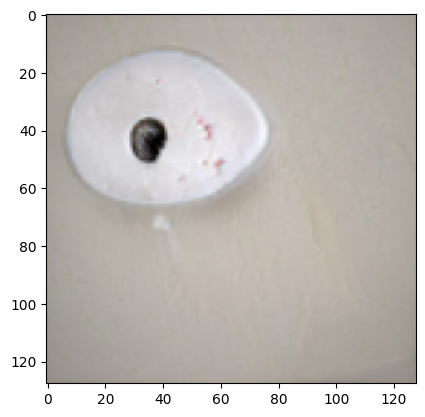

In [9]:
img = Image.open("genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/999_biggan_00198.png")
plt.imshow(img)


Processing images: 100%|██████████| 1000/1000 [01:15<00:00, 13.33it/s]


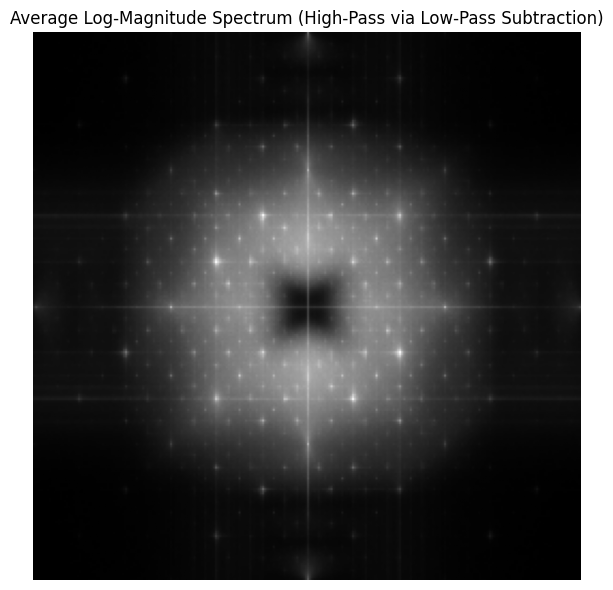

In [7]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/'  
N_IMAGES = 1000
IMAGE_SIZE = 256

cutoff = 10        # Cutoff frequency
fs = 100           # Sampling frequency
order = 2
btype = 'low'      

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)  

# Get first 1000 image files
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    # Load and preprocess with PIL
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #pply low-pass Butterworth filter
    lowpass = np.zeros_like(img_np) 
    for i in range(img_np.shape[0]):
        lowpass[i, :] = filtfilt(b, a, img_np[i, :])
    for j in range(img_np.shape[1]):
        lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

    highpass = img_np - lowpass    

    # FFT and log-magnitude spectrum of high-pass 
    f = np.fft.fft2(highpass)      
    fshift = np.fft.fftshift(f)
    magnitude = np.log(1 + np.abs(fshift))

    spectra.append(magnitude)

#Average spectrum visualization 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum (High-Pass via Low-Pass Subtraction)") 
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images: 100%|██████████| 1/1 [00:00<00:00, 13.91it/s]


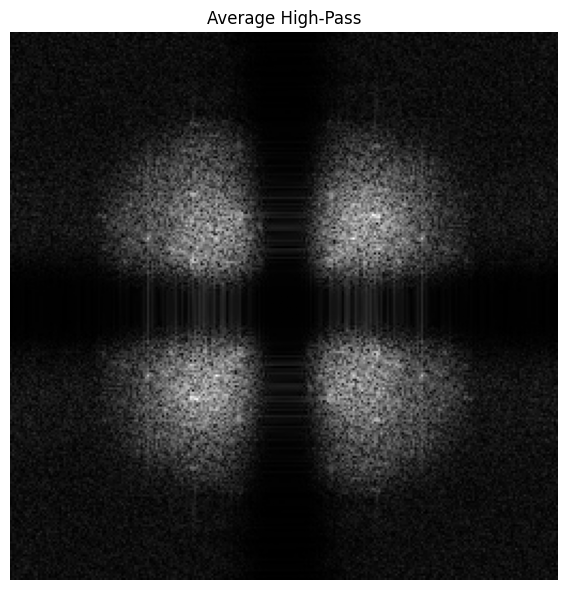

In [11]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/'
N_IMAGES = 1
IMAGE_SIZE = 256

cutoff = 10        # Cutoff frequency
fs = 100           # Sampling frequency
order = 2
btype = 'high'      

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)  

# Get first 1000 image files
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    # Load and preprocess with PIL
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #pply high-pass Butterworth filter
    highpass = np.zeros_like(img_np) 
    for i in range(img_np.shape[0]):
        highpass[i, :] = filtfilt(b, a, img_np[i, :])
    for j in range(img_np.shape[1]):
        highpass[:, j] = filtfilt(b, a, highpass[:, j])


    # FFT and log-magnitude spectrum of high-pass 
    f = np.fft.fft2(highpass)      
    fshift = np.fft.fftshift(f)
    magnitude = np.log(1 + np.abs(fshift))

    spectra.append(magnitude)

#Average spectrum visualization 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average High-Pass") 
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images: 100%|██████████| 100/100 [00:06<00:00, 14.45it/s]


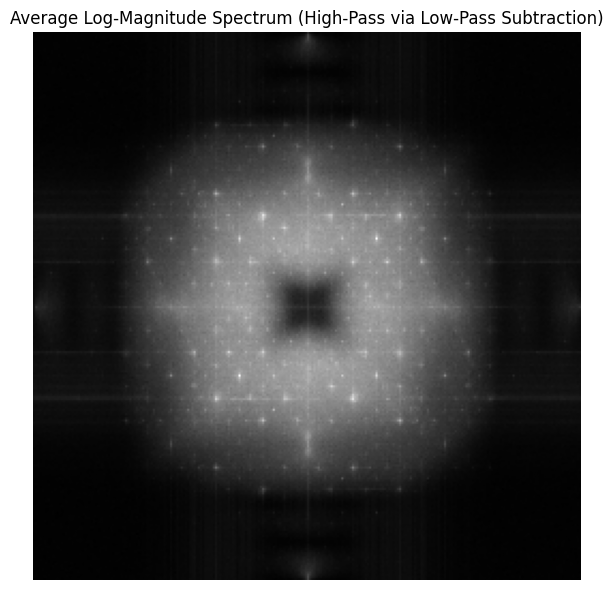

In [ ]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/'  
N_IMAGES = 100
IMAGE_SIZE = 256

cutoff = 10        # Cutoff frequency
fs = 100           # Sampling frequency
order = 2
btype = 'low'      

b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)  

# Get first 1000 image files
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    # Load and preprocess with PIL
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #pply low-pass Butterworth filter
    lowpass = np.zeros_like(img_np) 
    for i in range(img_np.shape[0]):
        lowpass[i, :] = filtfilt(b, a, img_np[i, :])
    for j in range(img_np.shape[1]):
        lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

    highpass = img_np - lowpass    

    # FFT and log-magnitude spectrum of high-pass 
    f = np.fft.fft2(highpass)      
    fshift = np.fft.fftshift(f)
    magnitude = np.log(1 + np.abs(fshift))

    spectra.append(magnitude)

#Average spectrum visualization 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum (High-Pass via Low-Pass Subtraction)") 
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images: 100%|██████████| 100/100 [00:39<00:00,  2.51it/s]


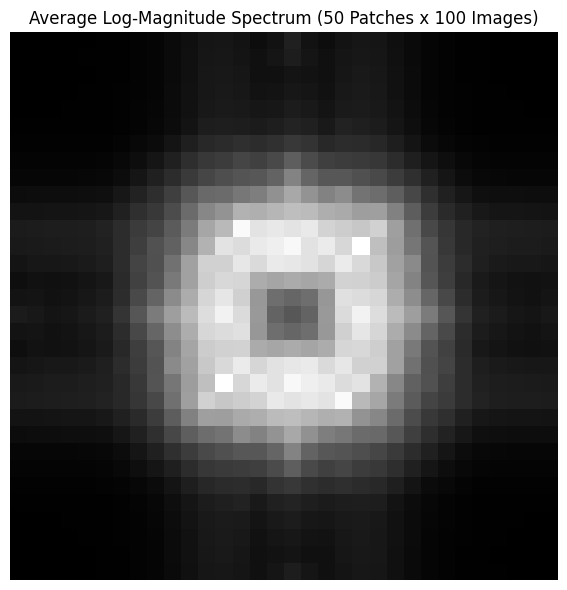

In [ ]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/' 
N_IMAGES = 100
PATCHES_PER_IMAGE = 50
IMAGE_SIZE = 256
PATCH_SIZE = 32  


cutoff = 10
fs = 100
order = 2
btype = 'low' 

#  Design Butterworth Filter 
b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

# Load image file paths 
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    #  Load and resize image 
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, IMAGE_SIZE, PATCH_SIZE):
        for x in range(0, IMAGE_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_IMAGE:
                break
        if len(patches) == PATCHES_PER_IMAGE:
            break

    #  Process each patch 
    for patch in patches:
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum (50 Patches x 100 Images)")
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images: 100%|██████████| 1/1 [00:00<00:00,  1.78it/s]


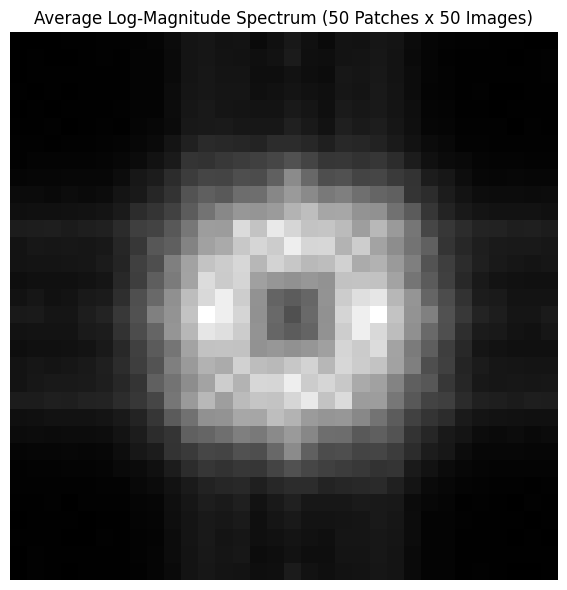

In [19]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/ai/' 
N_IMAGES = 1
PATCHES_PER_IMAGE = 60
IMAGE_SIZE = 256
PATCH_SIZE = 32  


cutoff = 10
fs = 100
order = 2
btype = 'low' 

#  Design Butterworth Filter 
b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

# Load image file paths 
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    #  Load and resize image 
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, IMAGE_SIZE, PATCH_SIZE):
        for x in range(0, IMAGE_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_IMAGE:
                break
        if len(patches) == PATCHES_PER_IMAGE:
            break

    #  Process each patch 
    for patch in patches:
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum (50 Patches x 50 Images)")
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images: 100%|██████████| 20/20 [00:08<00:00,  2.23it/s]


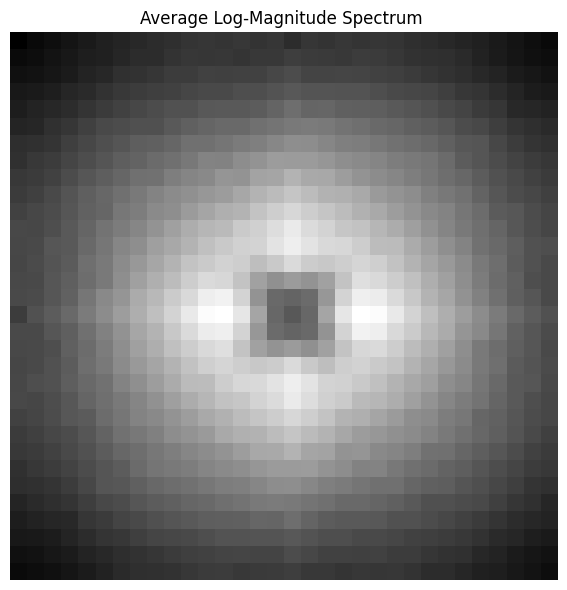

In [13]:
IMAGE_DIR = 'genimage/BigGAN/imagenet_ai_0419_biggan/train/nature/' 
N_IMAGES = 20
PATCHES_PER_IMAGE = 50
IMAGE_SIZE = 256
PATCH_SIZE = 32  


cutoff = 10
fs = 100
order = 2
btype = 'low' 

#  Design Butterworth Filter 
b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

# Load image file paths 
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    #  Load and resize image 
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, IMAGE_SIZE, PATCH_SIZE):
        for x in range(0, IMAGE_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_IMAGE:
                break
        if len(patches) == PATCHES_PER_IMAGE:
            break

    #  Process each patch 
    for patch in patches:
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum ")
plt.axis('off')
plt.tight_layout()
plt.show()

Processing images:   0%|          | 0/100 [00:00<?, ?it/s]

Processing images: 100%|██████████| 100/100 [00:42<00:00,  2.38it/s]


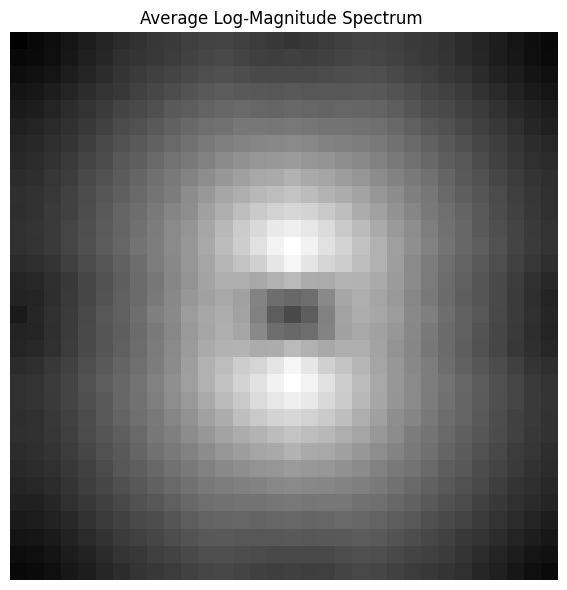

In [5]:
#WUKONG AI
IMAGE_DIR = 'genimage/wukong/imagenet_ai_0424_wukong/train/ai/' 
N_IMAGES = 100
PATCHES_PER_IMAGE = 50
IMAGE_SIZE = 256
PATCH_SIZE = 32  


cutoff = 10
fs = 100
order = 2
btype = 'low' 

#  Design Butterworth Filter 
b, a = butter(N=order, Wn=cutoff / (0.5 * fs), btype=btype)

# Load image file paths 
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
])[:N_IMAGES]

spectra = []

for fname in tqdm(image_files, desc="Processing images"):
    path = os.path.join(IMAGE_DIR, fname)

    #  Load and resize image 
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        img_np = np.asarray(img, dtype=np.float32) / 255.0
    except Exception as e:
        print(f"Skipping {fname}: {e}")
        continue

    #  Extract non-overlapping patches 
    patches = []
    for y in range(0, IMAGE_SIZE, PATCH_SIZE):
        for x in range(0, IMAGE_SIZE, PATCH_SIZE):
            patch = img_np[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            if patch.shape == (PATCH_SIZE, PATCH_SIZE):
                patches.append(patch)
            if len(patches) == PATCHES_PER_IMAGE:
                break
        if len(patches) == PATCHES_PER_IMAGE:
            break

    #  Process each patch 
    for patch in patches:
        lowpass = np.zeros_like(patch)
        for i in range(patch.shape[0]):
            lowpass[i, :] = filtfilt(b, a, patch[i, :])
        for j in range(patch.shape[1]):
            lowpass[:, j] = filtfilt(b, a, lowpass[:, j])

        highpass = patch - lowpass

        # FFT and log spectrum
        f = np.fft.fft2(highpass)
        fshift = np.fft.fftshift(f)
        magnitude = np.log(1 + np.abs(fshift))

        spectra.append(magnitude)

#  Average log-magnitude spectrum of all patches 
spectra = np.array(spectra)
avg_spectrum = np.mean(spectra, axis=0)

plt.figure(figsize=(6, 6))
plt.imshow(avg_spectrum, cmap='gray')
plt.title("Average Log-Magnitude Spectrum ")
plt.axis('off')
plt.tight_layout()
plt.show()